      FL_DATE                AIRLINE                AIRLINE_DOT AIRLINE_CODE  \
0  2019-01-09  United Air Lines Inc.  United Air Lines Inc.: UA           UA   
1  2022-11-19   Delta Air Lines Inc.   Delta Air Lines Inc.: DL           DL   
2  2022-07-22  United Air Lines Inc.  United Air Lines Inc.: UA           UA   
3  2023-03-06   Delta Air Lines Inc.   Delta Air Lines Inc.: DL           DL   
4  2020-02-23       Spirit Air Lines       Spirit Air Lines: NK           NK   

   DOT_CODE  FL_NUMBER ORIGIN          ORIGIN_CITY DEST  \
0     19977       1562    FLL  Fort Lauderdale, FL  EWR   
1     19790       1149    MSP      Minneapolis, MN  SEA   
2     19977        459    DEN           Denver, CO  MSP   
3     19790       2295    MSP      Minneapolis, MN  SFO   
4     20416        407    MCO          Orlando, FL  DFW   

               DEST_CITY  ...  DIVERTED  CRS_ELAPSED_TIME  ELAPSED_TIME  \
0             Newark, NJ  ...       0.0             186.0         176.0   
1            S

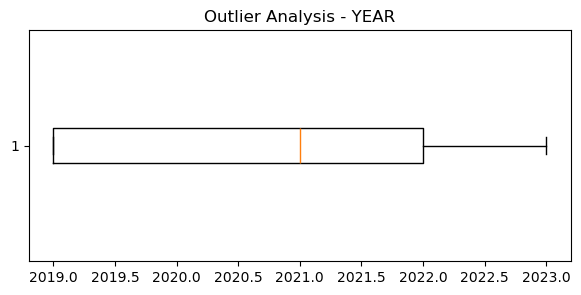

MONTH Outliers: 0


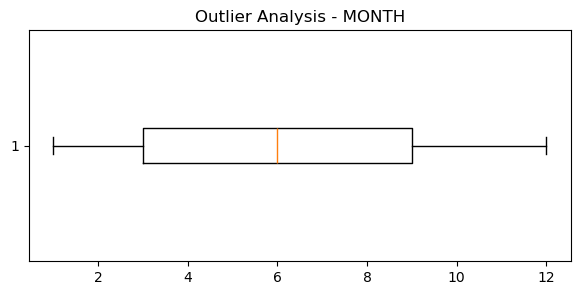

DAY Outliers: 0


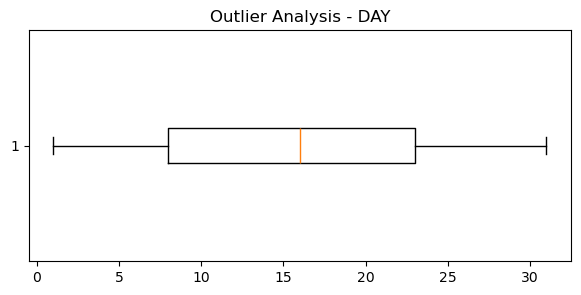

DAY_OF_WEEK Outliers: 0


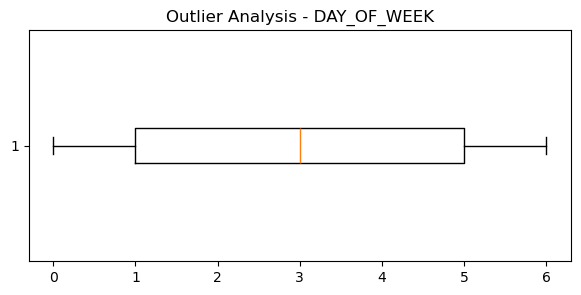

DISTANCE Outliers: 2740


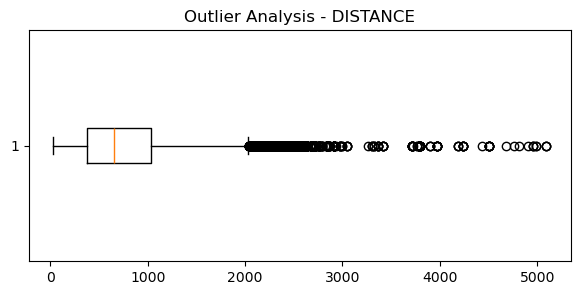

DEP_DELAY Outliers: 6936


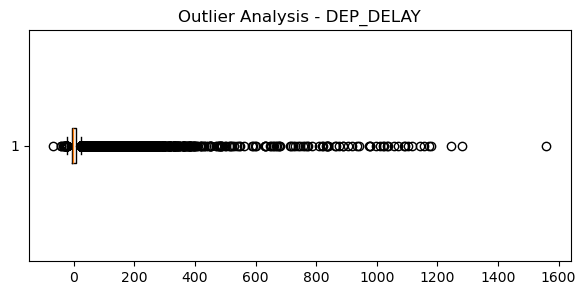

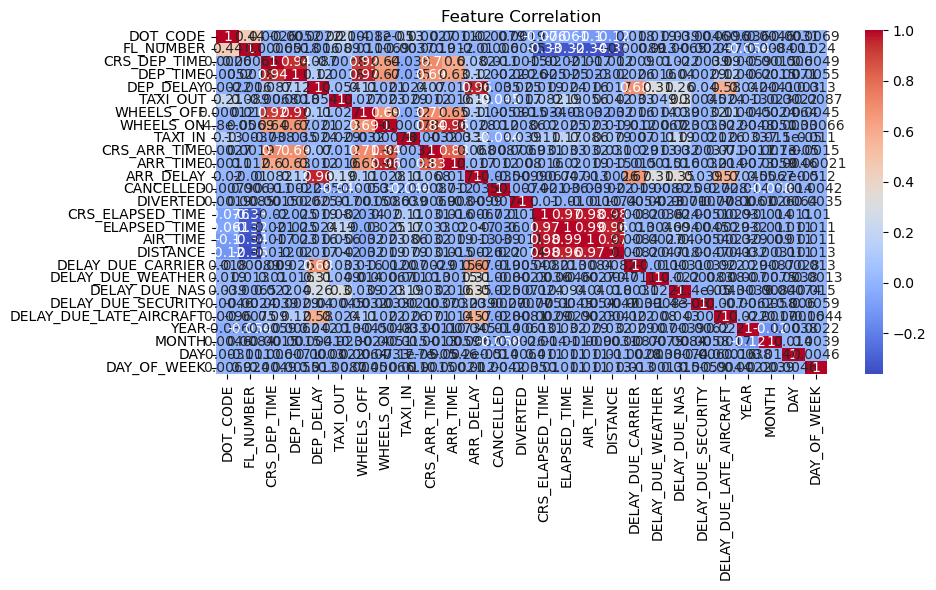

Training data: (40000, 9)
Testing data: (10000, 9)
Numerical columns: ['YEAR', 'MONTH', 'DAY', 'DAY_OF_WEEK', 'DISTANCE', 'DEP_DELAY']
Categorical columns: ['AIRLINE', 'ORIGIN', 'DEST']
Linear Regression Results
MAE: 9.278751587966072
RMSE: 15.748852662545145
R2: 0.898196509613051
CV Scores: [0.91160032 0.92879829 0.9360246  0.9315084  0.92470226]
Average CV Score: 0.9265267728364643
Random Forest
MAE: 9.675144666666666
RMSE: 16.15936645774346
R2: 0.8928200653226391
Fitting 3 folds for each of 6 candidates, totalling 18 fits
Best Parameters:
{'model__max_depth': 10, 'model__n_estimators': 100}
Best Score:
0.9225649670644769
Final Model
MAE: 9.367280689064545
RMSE: 15.865239814150817
R2: 0.8966862535522996
                 Model       MAE       RMSE  R2 Score
0    Linear Regression  9.278752  15.748853  0.898197
2  Tuned Random Forest  9.367281  15.865240  0.896686
1        Random Forest  9.675145  16.159366  0.892820
              Feature  Importance
5      num__DEP_DELAY    0.984549
4

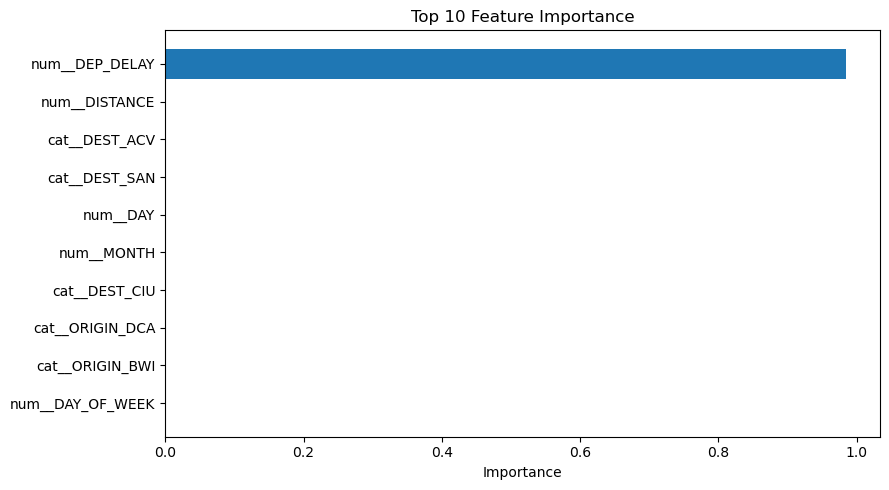

Model saved successfully!


In [4]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

from sklearn.model_selection import cross_val_score
from sklearn.model_selection import GridSearchCV

from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv(
     r"C:\Users\bakki\Downloads\archive\flights_sample_3m.csv",
    nrows=50000
)
print(df.head())
print(df.shape)
print(df.info())
print(df.columns.tolist())
print(df.describe())
print("Duplicates:",df.duplicated().sum())

print(df.isnull().sum())
# Check missing percentage
print(df.isnull().mean()*100)

num_cols=df.select_dtypes(include=["int64","float64"]).columns
cat_cols=df.select_dtypes(include="object").columns
df[num_cols]=df[num_cols].fillna(df[num_cols].median())
df[cat_cols]=df[cat_cols].fillna(df[cat_cols].mode().iloc[0])

num_cols

cat_cols

print(df.isnull().sum())
print(df.columns.tolist())

#  Clean target column

target = "ARR_DELAY"
df[target] = pd.to_numeric(df[target], errors="coerce")

# Remove rows where target is missing
df = df.dropna(subset=[target]).copy()

print("Missing target values:", df[target].isnull().sum())
print("Dataset shape after target cleaning:", df.shape)

#  Feature engineering 

df["FL_DATE"] = pd.to_datetime(df["FL_DATE"], errors="coerce")
df = df.dropna(subset=["FL_DATE"]).copy()
df["YEAR"] = df["FL_DATE"].dt.year
df["MONTH"] = df["FL_DATE"].dt.month
df["DAY"] = df["FL_DATE"].dt.day
df["DAY_OF_WEEK"] = df["FL_DATE"].dt.dayofweek

df = df.drop(columns=["FL_DATE"])

print(df.head())

#  Feature selection

features = [
    "YEAR",
    "MONTH",
    "DAY",
    "DAY_OF_WEEK",
    "AIRLINE",
    "ORIGIN",
    "DEST",
    "DISTANCE",
    "DEP_DELAY"
]

X = df[features].copy()
y = df[target].copy()

print("X shape:", X.shape)
print("y shape:", y.shape)
print(X.head())

# Save cleaned dataset
df.to_csv("cleaned_data.csv", index=False)

print("Cleaned CSV file saved successfully!")


# Outlier analysis 

numeric_feature_cols = X.select_dtypes(include=np.number).columns.tolist()

for col in numeric_feature_cols:
    q1 = X[col].quantile(0.25)
    q3 = X[col].quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    outliers = (
        (X[col] < lower) |
        (X[col] > upper)
    ).sum()

    print(col, "Outliers:", outliers)

    plt.figure(figsize=(7, 3))
    plt.boxplot(X[col].dropna(), vert=False)
    plt.title("Outlier Analysis - " + col)
    plt.show()
plt.figure(figsize=(10,6))
sns.heatmap(
    df.select_dtypes(include="number").corr(),
    annot=True,
    cmap="coolwarm"
)

plt.title("Feature Correlation")
plt.tight_layout()
plt.show()

# Train-Test Split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)
# numerical+categorical columns

num_cols = X.select_dtypes(
    include=np.number
).columns.tolist()

cat_cols = X.select_dtypes(
    include="object"
).columns.tolist()
print("Numerical columns:",num_cols)
print("Categorical columns:",cat_cols)

# Preprocessing pipeline

num_process = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

cat_process = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", num_process, num_cols),
    ("cat", cat_process, cat_cols)
])

# Base model

base_model = Pipeline([
    ("preprocessor", preprocessor),

    ("model", LinearRegression())
])

base_model.fit(X_train, y_train)

base_pred = base_model.predict(X_test)

# Base model evaluation

print("Linear Regression Results")

print("MAE:",
      mean_absolute_error(y_test, base_pred))

print("RMSE:",
      np.sqrt(mean_squared_error(y_test, base_pred)))

print("R2:",
      r2_score(y_test, base_pred))

# Cross validation

cv_scores = cross_val_score(
    base_model,
    X_train,
    y_train,
    cv=5,
    scoring="r2",
    n_jobs=-1
)

print("CV Scores:", cv_scores)
print("Average CV Score:", cv_scores.mean())

# Ensemble algorithm-random forest

rf_model = Pipeline([
    ("preprocessor", preprocessor),

    ("model",
     RandomForestRegressor(
         n_estimators=50,
         random_state=42,
         n_jobs=-1
     ))
])

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)

# Random forest evaluation

print("Random Forest")

print("MAE:",
      mean_absolute_error(y_test, rf_pred))

print("RMSE:",
      np.sqrt(mean_squared_error(y_test, rf_pred)))

print("R2:",
      r2_score(y_test, rf_pred))


# Hyper parameter tuning

params = {
    "model__n_estimators": [50,100],
    "model__max_depth":[5,10,None]
}

grid = GridSearchCV(
    estimator=rf_model,
    param_grid=params,
    cv=3,
    scoring="r2",
    n_jobs=-1,
    verbose=1
)

grid.fit(X_train, y_train)

print("Best Parameters:")
print(grid.best_params_)
print("Best Score:")
print(grid.best_score_)

# Final model

final_model = grid.best_estimator_

final_pred = final_model.predict(X_test)

print("Final Model")

print("MAE:",
      mean_absolute_error(y_test, final_pred))

print("RMSE:",
      np.sqrt(mean_squared_error(y_test, final_pred)))

print("R2:",
      r2_score(y_test, final_pred))

# Model comparison
results = []

models = {
    "Linear Regression": base_pred,
    "Random Forest": rf_pred,
    "Tuned Random Forest": final_pred
}

for name, predictions in models.items():

    mae = mean_absolute_error(y_test, predictions)

    rmse = np.sqrt(
        mean_squared_error(y_test, predictions)
    )

    r2 = r2_score(y_test, predictions)

    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2 Score": r2
    })

results_df = pd.DataFrame(results)

print(results_df.sort_values(
    by="R2 Score",
    ascending=False
))

#  Feature importance

feature_names = final_model.named_steps["preprocessor"].get_feature_names_out()
importance = final_model.named_steps["model"].feature_importances_

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance
})
feature_importance=feature_importance.sort_values(by="Importance", ascending=False)

print(feature_importance.head(15))

top = feature_importance.head(10).sort_values(by="Importance")

plt.figure(figsize=(9, 5))
plt.barh(top["Feature"], top["Importance"])
plt.xlabel("Importance")
plt.title("Top 10 Feature Importance")
plt.tight_layout()
plt.show()
# save the final model
import joblib

joblib.dump(final_model, "flight_model.pkl")
print("Model saved successfully!")
